In [1]:
import pandas as pd

In [2]:
cutadapt = pd.read_csv('data/cox2_th_cutadapt/cutadapt-info-parsed.tsv', sep='\t')
cutadapt

,accession,start_forward,end_forward,errors_forward,primer_size_forward,primer_name_forward,primer_seq_forward,left_seq_forward,right_seq_forward,start_reverse,end_reverse,primer_size_reverse,errors_reverse,primer_name_reverse,primer_seq_reverse,left_seq_reverse,right_seq_reverse,reverse_complement
0,AB095053.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,287.0,309.0,22.0,0.0,1;2,GGTATTGGAGTTATGAATATTC,AACTCCAGTAATGGAAGGTATTATTAACTTTCATCATGATTTAATG...,CGATAATTTAGAATTTGCTGATGAACCTTTAATTTTTGATAGTTAT...,False
1,AB095054.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,287.0,309.0,22.0,0.0,1;2,GGTATTGGAGTTATGAATATTC,AACTCCAGTAATGGAAGGTATTATTAACTTTCATCATGATTTAATG...,CGATAATTTGGAATTTGCTGACGAACCTTTAATTTTTGATAGTTAT...,False
2,AB095055.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,287.0,309.0,22.0,0.0,1;2,GGTATTGGAGTTATGAATATTC,AACTCCAGTAATGGAAGGTATTATTAACTTTCATCATGATTTAATG...,CGATAATTTGGAATTTGCTGACGAACCTTTAATTTTTGATAGTTAT...,False
3,AB095056.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,287.0,309.0,22.0,0.0,1;2,GGTATTGGAGTTATGAATATTC,AACTCCAGTAATGGAAGGTATTATTAACTTTCATCATGATTTAATG...,CGATAATTTAGAATTTGCTGATGAACCTTTAATTTTTGATAGTTAT...,False
4,AB095057.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,287.0,309.0,22.0,1.0,1;2,GGTATTGGAGTTATGAGTATTC,AACACCTGTAATGGAAGGTATTATAAACTTTCATCATGATTTAATG...,TGATAATTTAGAATTCGCAGATGAACCTTTAATTTTTGATAGTTAT...,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3857,PV956200.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,290.0,312.0,22.0,0.0,1;2,GGTACTGGAGTTATGAATATTC,AGCAACTCCAGTTATGGAAGGTATTATTAACTTTCATCATGATTTA...,CGATAATTTAGAATTTTCCGATGAACCTTTAATTTTCGATAGTTAT...,False
3858,PV956201.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,247.0,269.0,22.0,0.0,1;2,GGTACTGGAGTTATGAATATTC,TTAATGTTTTTTTTAATTATCGTTACTGTATTTGTTTGTTGGATGT...,CGATAATTTAGAATTTTCCGATGAACCTTTAATTTTCGATAGTTAT...,False
3859,PV995064.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,242.0,264.0,22.0,0.0,1;2,GGTATTGGAGTTATGAATATTC,GTTTTTTTTAATTATTGTTACTGTATTTGTATGTTGGATGTTATTT...,AGATAATTTAGAATTTTCTGATGAACCTTTAATTTTTGATAGTTAT...,False
3860,PV995065.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,242.0,264.0,22.0,0.0,1;2,GGTATTGGAGTTATGAATATTC,GTTTTTTTTAATTATTGTTACTGTATTTGTATGTTGGATGTTATTT...,AGATAATTTAGAATTTTCTGATGAACCTTTAATTTTTGATAGTTAT...,False


In [3]:
f_primer_size = 22

with open('primer_f.fasta', 'w') as out:
    for _, row in cutadapt.iterrows():
        if pd.isna(row['primer_size_forward']):
            continue
        if row['primer_size_forward'] > f_primer_size:
            continue
        out.write(f">{row['accession']}\n{row['primer_seq_forward']}\n")
        if row['primer_size_forward'] < f_primer_size and not pd.isna(row['left_seq_forward']):
            missing = f_primer_size - row['primer_size_forward']
            to_extract = int(min(len(row['left_seq_forward']), missing))
            row['primer_seq_forward'] = f"{str(row['left_seq_forward'])[-to_extract:]}{row['primer_seq_forward']}"
cutadapt

,accession,start_forward,end_forward,errors_forward,primer_size_forward,primer_name_forward,primer_seq_forward,left_seq_forward,right_seq_forward,start_reverse,end_reverse,primer_size_reverse,errors_reverse,primer_name_reverse,primer_seq_reverse,left_seq_reverse,right_seq_reverse,reverse_complement
0,AB095053.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,287.0,309.0,22.0,0.0,1;2,GGTATTGGAGTTATGAATATTC,AACTCCAGTAATGGAAGGTATTATTAACTTTCATCATGATTTAATG...,CGATAATTTAGAATTTGCTGATGAACCTTTAATTTTTGATAGTTAT...,False
1,AB095054.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,287.0,309.0,22.0,0.0,1;2,GGTATTGGAGTTATGAATATTC,AACTCCAGTAATGGAAGGTATTATTAACTTTCATCATGATTTAATG...,CGATAATTTGGAATTTGCTGACGAACCTTTAATTTTTGATAGTTAT...,False
2,AB095055.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,287.0,309.0,22.0,0.0,1;2,GGTATTGGAGTTATGAATATTC,AACTCCAGTAATGGAAGGTATTATTAACTTTCATCATGATTTAATG...,CGATAATTTGGAATTTGCTGACGAACCTTTAATTTTTGATAGTTAT...,False
3,AB095056.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,287.0,309.0,22.0,0.0,1;2,GGTATTGGAGTTATGAATATTC,AACTCCAGTAATGGAAGGTATTATTAACTTTCATCATGATTTAATG...,CGATAATTTAGAATTTGCTGATGAACCTTTAATTTTTGATAGTTAT...,False
4,AB095057.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,287.0,309.0,22.0,1.0,1;2,GGTATTGGAGTTATGAGTATTC,AACACCTGTAATGGAAGGTATTATAAACTTTCATCATGATTTAATG...,TGATAATTTAGAATTCGCAGATGAACCTTTAATTTTTGATAGTTAT...,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3857,PV956200.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,290.0,312.0,22.0,0.0,1;2,GGTACTGGAGTTATGAATATTC,AGCAACTCCAGTTATGGAAGGTATTATTAACTTTCATCATGATTTA...,CGATAATTTAGAATTTTCCGATGAACCTTTAATTTTCGATAGTTAT...,False
3858,PV956201.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,247.0,269.0,22.0,0.0,1;2,GGTACTGGAGTTATGAATATTC,TTAATGTTTTTTTTAATTATCGTTACTGTATTTGTTTGTTGGATGT...,CGATAATTTAGAATTTTCCGATGAACCTTTAATTTTCGATAGTTAT...,False
3859,PV995064.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,242.0,264.0,22.0,0.0,1;2,GGTATTGGAGTTATGAATATTC,GTTTTTTTTAATTATTGTTACTGTATTTGTATGTTGGATGTTATTT...,AGATAATTTAGAATTTTCTGATGAACCTTTAATTTTTGATAGTTAT...,False
3860,PV995065.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,242.0,264.0,22.0,0.0,1;2,GGTATTGGAGTTATGAATATTC,GTTTTTTTTAATTATTGTTACTGTATTTGTATGTTGGATGTTATTT...,AGATAATTTAGAATTTTCTGATGAACCTTTAATTTTTGATAGTTAT...,False


In [4]:
from Bio import SeqIO
import matplotlib.pyplot as plt
%matplotlib inline
import logomaker as lm

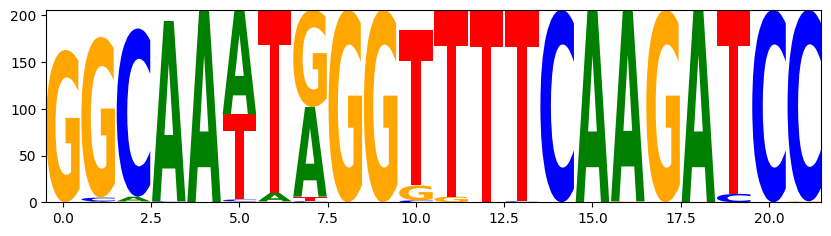

In [5]:
seqs = [str(record.seq).upper() for record in SeqIO.parse('primer_f-msa.fasta', 'fasta')]
counts_df = lm.alignment_to_matrix(sequences=seqs, to_type='counts', characters_to_ignore='-N')
lm.Logo(counts_df)


##### atgcfreq = 1.000000
nseq =  129
distance =  ktuples
iterate =  2
cycle =  2
nthread = 0
generating 200PAM scoring matrix for nucleotides ... done
done
done
scoremtx = -1
Gap Penalty = -1.53, +0.00, +0.00

tuplesize = 6, dorp = d


Making a distance matrix ..
  121 / 129
done.

Constructing a UPGMA tree ... 
  120 / 129
done.

Progressive alignment ... 
STEP   128 / 128 d
done.

disttbfast (nuc) Version 7.055b alg=A, model=DNA200 (2),  1.530 ( 4.590), -0.000 (-0.000)
0 thread(s)
nthread = 0
blosum 62 / kimura 200
generating 200PAM scoring matrix for nucleotides ... done
done
done
scoremtx = -1
Gap Penalty = -1.53, +0.00, +0.00
Making a distance matrix .. 
  120 / 128
done.

Constructing a UPGMA tree ... 
  120 / 129
done.

Progressive alignment ... 
STEP   128 /128 d
done.
tbfast (nuc) Version 7.055b alg=A, model=DNA200 (2),  1.530 ( 4.590), -0.000 (-0.000)
0 thread(s)
nthread = 0
generating 200PAM scoring matrix for nucleotides ... done
done
done
scoremtx = -1
dndpre (nuc) Versi

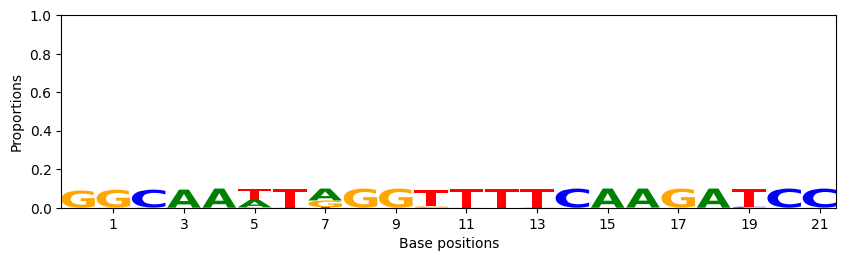

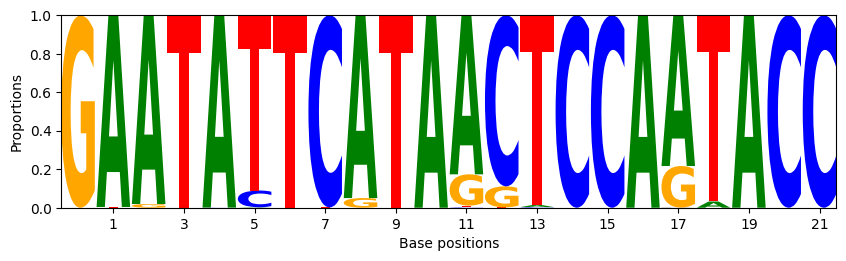

In [6]:
from src import primer

primer.logo_plot('data/cox2_th_cutadapt/cutadapt-info-parsed.tsv', 'data/cox2_th_cutadapt/cox2_th_cutadapt-meta.csv', 'data/cox2_th_cutadapt/primer_f.fasta', 22, 'data/cox2_th_cutadapt/primer_f.svg', 'forward')
primer.logo_plot('data/cox2_th_cutadapt/cutadapt-info-parsed.tsv', 'data/cox2_th_cutadapt/cox2_th_cutadapt-meta.csv', 'data/cox2_th_cutadapt/primer_r.fasta', 22, 'data/cox2_th_cutadapt/primer_r.svg', 'reverse')

In [7]:
meta = pd.read_csv('data/cox2_th_cutadapt/cox2_th_cutadapt-meta.csv', sep='\t')
meta

,accession,creation_date,title,authors,sequence_length,organism_name,tax_id_x,organism,organelle,mol_type,...,trimed_seq_len,tax_id_y,species,domain,kingdom,phylum,class,order,family,genus
0,MW006635.1,23-NOV-2020,Globisporangium irregulare isolate UM1087 cyto...,"Callaghan,S.E.",621,Globisporangium irregulare,36331,Globisporangium irregulare,mitochondrion,genomic DNA,...,315,36331,Globisporangium irregulare,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Pythiales,Pythiaceae,Globisporangium
1,PP444835.1,14-MAR-2024,Peronosclerospora maydis isolate Tabanan cytoc...,"Sugiarta,D., Susanta Wirya,G.A. and Agung Phab...",346,Peronosclerospora maydis,886949,Peronosclerospora maydis,mitochondrion,genomic DNA,...,308,886949,Peronosclerospora maydis,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Peronosporales,Peronosporaceae,Peronosclerospora
2,OP727296.1,11-NOV-2023,Peronosclerospora neglecta culture BRIP:71135 ...,"Muis,A., Ryley,M.J., Tan,Y.P., Suharjo,R., Non...",409,Peronosclerospora neglecta,3090892,Peronosclerospora neglecta,mitochondrion,genomic DNA,...,227,3090892,Peronosclerospora neglecta,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Peronosporales,Peronosporaceae,Peronosclerospora
3,KM819519.1,27-JAN-2015,Pythiogeton ramosum isolate SC2.7.2 cytochrome...,"Le,D.P., Smith,M.K. and Aitken,E.",614,Pythiogeton ramosum,1217586,Pythiogeton ramosum,mitochondrion,genomic DNA,...,307,1217586,Pythiogeton ramosum,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Pythiales,Pythiogetonaceae,Pythiogeton
4,DQ071412.1,22-JUL-2009,Phytophthora megasperma strain CH95 cytochrome...,"Villa,N.O., Kageyama,K., Asano,T. and Suga,H.",563,Phytophthora megasperma,4788,Phytophthora megasperma,mitochondrion,genomic DNA,...,277,4788,Phytophthora megasperma,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Peronosporales,Peronosporaceae,Phytophthora
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1292,MK602199.1,29-APR-2020,Globisporangium spinosum isolate C9 cytochrome...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium spinosum,2125998,Globisporangium spinosum,mitochondrion,genomic DNA,...,211,2125998,Globisporangium spinosum,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Pythiales,Pythiaceae,Globisporangium
1293,MK602203.1,29-APR-2020,Globisporangium irregulare isolate C13 cytochr...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium irregulare,36331,Globisporangium irregulare,mitochondrion,genomic DNA,...,211,36331,Globisporangium irregulare,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Pythiales,Pythiaceae,Globisporangium
1294,MK602204.1,29-APR-2020,Globisporangium irregulare isolate C14 cytochr...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium irregulare,36331,Globisporangium irregulare,mitochondrion,genomic DNA,...,211,36331,Globisporangium irregulare,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Pythiales,Pythiaceae,Globisporangium
1295,MK602213.1,29-APR-2020,Globisporangium irregulare isolate C24 cytochr...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium irregulare,36331,Globisporangium irregulare,mitochondrion,genomic DNA,...,211,36331,Globisporangium irregulare,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Pythiales,Pythiaceae,Globisporangium


In [8]:
import matplotlib.pyplot as plt

In [9]:
rank = 'order'

groups = meta.groupby(rank)
seq_counts = groups.size()
species_counts = groups['species'].nunique()

diversity = pd.DataFrame({
    "Sequences": seq_counts,
    "Species": species_counts
})
diversity = diversity.sort_values("Sequences", ascending=True)

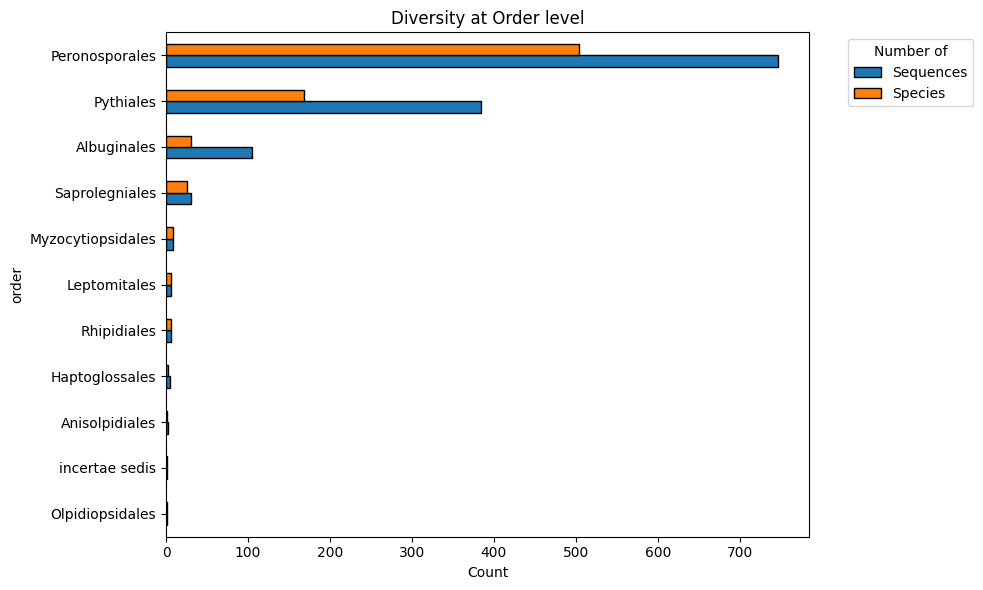

In [10]:
ax = diversity.plot(kind="barh", figsize=(10,6), edgecolor='black', linewidth=1)
plt.title(f"Diversity at {rank.capitalize()} level")
plt.xlabel("Count")
#plt.xticks(rotation=45, ha="right")
plt.legend(title="Number of", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [11]:
from Bio import SeqIO
import pandas as pd

def fasta_to_lengths(fasta_file):
    lengths = []
    for record in SeqIO.parse(fasta_file, "fasta"):
        lengths.append({"accession": record.id, "trimmed_seq_len": len(str(record.seq))})
    return pd.DataFrame(lengths)
df_lengths = fasta_to_lengths('data/cox2_th_cutadapt/cox2_th_cutadapt-qiime.fa')
df = meta.merge(df_lengths, on="accession")
df

,accession,creation_date,title,authors,sequence_length,organism_name,tax_id_x,organism,organelle,mol_type,...,tax_id_y,species,domain,kingdom,phylum,class,order,family,genus,trimmed_seq_len
0,MW006635.1,23-NOV-2020,Globisporangium irregulare isolate UM1087 cyto...,"Callaghan,S.E.",621,Globisporangium irregulare,36331,Globisporangium irregulare,mitochondrion,genomic DNA,...,36331,Globisporangium irregulare,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Pythiales,Pythiaceae,Globisporangium,290
1,PP444835.1,14-MAR-2024,Peronosclerospora maydis isolate Tabanan cytoc...,"Sugiarta,D., Susanta Wirya,G.A. and Agung Phab...",346,Peronosclerospora maydis,886949,Peronosclerospora maydis,mitochondrion,genomic DNA,...,886949,Peronosclerospora maydis,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Peronosporales,Peronosporaceae,Peronosclerospora,290
2,OP727296.1,11-NOV-2023,Peronosclerospora neglecta culture BRIP:71135 ...,"Muis,A., Ryley,M.J., Tan,Y.P., Suharjo,R., Non...",409,Peronosclerospora neglecta,3090892,Peronosclerospora neglecta,mitochondrion,genomic DNA,...,3090892,Peronosclerospora neglecta,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Peronosporales,Peronosporaceae,Peronosclerospora,227
3,KM819519.1,27-JAN-2015,Pythiogeton ramosum isolate SC2.7.2 cytochrome...,"Le,D.P., Smith,M.K. and Aitken,E.",614,Pythiogeton ramosum,1217586,Pythiogeton ramosum,mitochondrion,genomic DNA,...,1217586,Pythiogeton ramosum,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Pythiales,Pythiogetonaceae,Pythiogeton,290
4,DQ071412.1,22-JUL-2009,Phytophthora megasperma strain CH95 cytochrome...,"Villa,N.O., Kageyama,K., Asano,T. and Suga,H.",563,Phytophthora megasperma,4788,Phytophthora megasperma,mitochondrion,genomic DNA,...,4788,Phytophthora megasperma,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Peronosporales,Peronosporaceae,Phytophthora,277
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1292,MK602199.1,29-APR-2020,Globisporangium spinosum isolate C9 cytochrome...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium spinosum,2125998,Globisporangium spinosum,mitochondrion,genomic DNA,...,2125998,Globisporangium spinosum,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Pythiales,Pythiaceae,Globisporangium,211
1293,MK602203.1,29-APR-2020,Globisporangium irregulare isolate C13 cytochr...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium irregulare,36331,Globisporangium irregulare,mitochondrion,genomic DNA,...,36331,Globisporangium irregulare,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Pythiales,Pythiaceae,Globisporangium,211
1294,MK602204.1,29-APR-2020,Globisporangium irregulare isolate C14 cytochr...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium irregulare,36331,Globisporangium irregulare,mitochondrion,genomic DNA,...,36331,Globisporangium irregulare,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Pythiales,Pythiaceae,Globisporangium,211
1295,MK602213.1,29-APR-2020,Globisporangium irregulare isolate C24 cytochr...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium irregulare,36331,Globisporangium irregulare,mitochondrion,genomic DNA,...,36331,Globisporangium irregulare,Eukaryota,Stramenopiles,Oomycota,Peronosporomycetes,Pythiales,Pythiaceae,Globisporangium,211


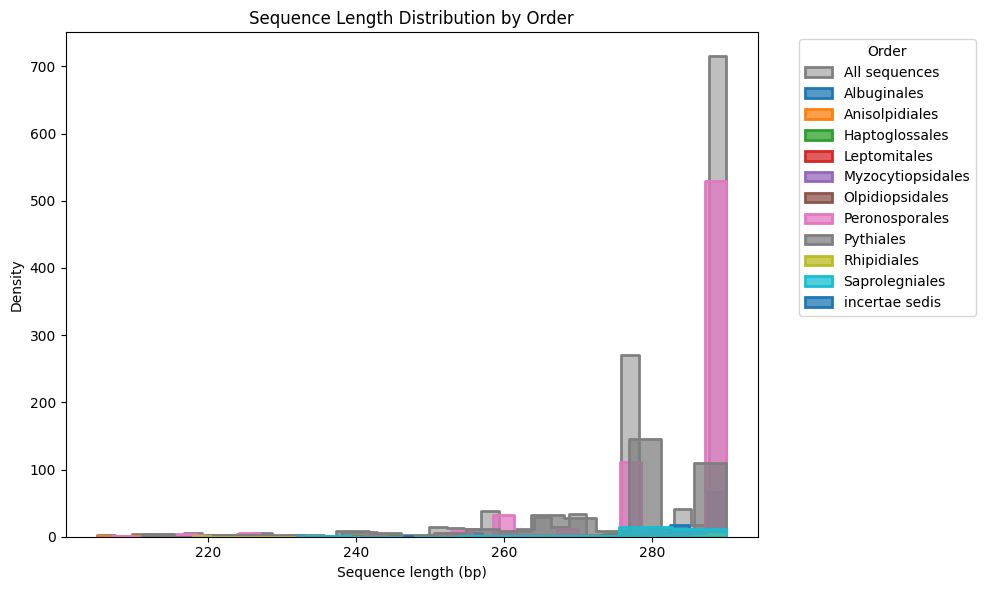

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_length_kde(df, rank_col, min_count=50):
    """
    Plot overall sequence length distribution and per-rank KDEs.

    Parameters
    ----------
    df : pd.DataFrame
        Must contain ['length', rank_col].
    rank_col : str
        Column to group by (e.g. 'phylum').
    min_count : int
        Minimum number of sequences for a taxon to be plotted.
    """
    plt.figure(figsize=(10,6))

    # background: all sequences (grey)
    sns.histplot(df["trimmed_seq_len"], color="grey", element='step', linewidth=2, fill=True,
                alpha=0.5, label="All sequences")

    # plot each taxon as a separate KDE curve
    for taxon, sub in df.groupby(rank_col):
        sns.histplot(sub["trimmed_seq_len"], element='step', linewidth=2, label=taxon)

    plt.title(f"Sequence Length Distribution by {rank_col.capitalize()}")
    plt.xlabel("Sequence length (bp)")
    plt.ylabel("Density")
    plt.legend(title=rank_col.capitalize(), bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

plot_length_kde(df, 'order')


In [13]:
def hist_column(df: pd.DataFrame, column_name: str, n_top_categories: int = 10):
    counts = df[column_name].value_counts(sort=True, ascending=False, dropna=True)
    top_counts = counts[:min(len(counts), n_top_categories)].sort_values(ascending=True)
    top_counts.plot.barh(linewidth=1, edgecolor='black').set_xlabel("count")

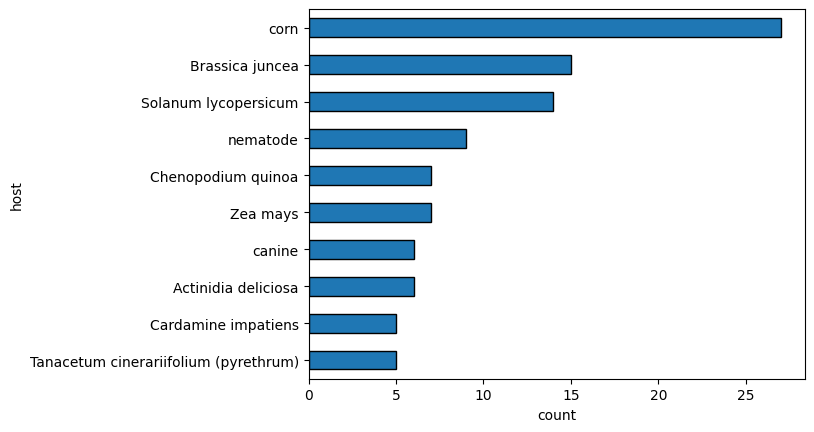

In [14]:
hist_column(meta, 'host')